# Applied AI Assignment 2 — Cross-Domain Sentiment Classification

Dataset: Multi-Domain Sentiment Dataset, version 2.0. Task: train on Books and evaluate on DVD, Electronics and Kitchen. The notebook runs exactly two traditional models and two deep models, with a baseline and refined version of each.

The dataset is downloaded from the official Johns Hopkins source. Raw data are not saved in the repository.

In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from assignment1.data import load_multidomain_dataset, dataset_summary
from assignment1.experiment import run_experiment
DATA_DIR = ROOT / 'data' / 'raw' / 'processed_acl'
RESULTS_DIR = ROOT / 'results'
SEED = 42

## 1. Dataset download and inspection

The official version 2.0 page provides a balanced binary archive in the processed ACL format. Each record stores word-feature counts followed by a sentiment label.

In [2]:
if not DATA_DIR.exists() or not any(DATA_DIR.rglob('processed.review.balanced')):
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'download_dataset.py')], check=True)
dataset = load_multidomain_dataset(DATA_DIR)
full_summary = pd.DataFrame(dataset_summary(dataset))
display(full_summary)

Dataset extracted to: /home/runner/work/shamim-vai-project/shamim-vai-project/assignment -1/data/raw/processed_acl


,domain,documents,positive,negative,unique_features
0,books,2000,1000,1000,195876
1,dvd,2000,1000,1000,188768
2,electronics,2000,1000,1000,111395
3,kitchen,2000,1000,1000,93468


## 2. Data analysis

The experiment uses a reproducible, class-balanced sample of up to 1,500 positive and 1,500 negative reviews per domain. The source split is stratified. Target domains are kept out of model fitting.

In [3]:
sample_counts = full_summary[['domain', 'positive', 'negative', 'documents']].copy()
display(sample_counts)
ax = full_summary.set_index('domain')[['positive', 'negative']].plot(kind='bar', figsize=(8,4))
ax.set_title('Full dataset class counts by domain')
ax.set_xlabel('Domain'); ax.set_ylabel('Reviews'); ax.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.show()

,domain,positive,negative,documents
0,books,1000,1000,2000
1,dvd,1000,1000,2000
2,electronics,1000,1000,2000
3,kitchen,1000,1000,2000


## 3. Model training and refinement

Traditional models: Logistic Regression and Linear SVM. Deep models: DNN and Residual MLP. Traditional refinements tune regularisation on validation F1. Neural refinements change the hidden architecture and regularisation, then use early stopping.

In [4]:
metrics = run_experiment(
    data_dir=DATA_DIR,
    output_dir=RESULTS_DIR,
    source_domain='books',
    target_domains=['dvd', 'electronics', 'kitchen'],
    max_per_class=1500,
    max_features=5000,
    seed=SEED,
)
display(metrics.sort_values(['evaluation', 'model', 'stage']))

,model,stage,evaluation,n_test,validation_f1,accuracy,precision,recall,f1,roc_auc
14,Deep Neural Network,baseline,cross_domain:dvd,2000,0.803922,0.7930,0.819869,0.751,0.783925,0.884115
15,Deep Neural Network,refined,cross_domain:dvd,2000,0.800000,0.7930,0.829955,0.737,0.780720,0.886894
12,Linear SVM,baseline,cross_domain:dvd,2000,0.797386,0.7935,0.823594,0.747,0.783429,0.882367
13,Linear SVM,refined,cross_domain:dvd,2000,0.808777,0.7940,0.797571,0.788,0.792757,0.872632
10,Logistic Regression,baseline,cross_domain:dvd,2000,0.773333,0.7865,0.834306,0.715,0.770059,0.870630
11,Logistic Regression,refined,cross_domain:dvd,2000,0.800000,0.7925,0.820372,0.749,0.783063,0.882419
9,Majority baseline,reference,cross_domain:dvd,2000,NaN,0.5000,0.000000,0.000,0.000000,NaN
16,Residual MLP,baseline,cross_domain:dvd,2000,0.809211,0.7950,0.832957,0.738,0.782609,0.879964
17,Residual MLP,refined,cross_domain:dvd,2000,0.000000,0.5000,0.000000,0.000,0.000000,0.868665
23,Deep Neural Network,baseline,cross_domain:electronics,2000,0.803922,0.7270,0.817927,0.584,0.681447,0.818588


## 4. Results and evaluation

The evaluation reports accuracy, precision, recall, F1-score and ROC-AUC. The same table is written to `results/metrics_summary.csv` and inserted into the LaTeX report.

In [5]:
refinement = pd.read_csv(RESULTS_DIR / 'refinement_comparison.csv')
display(refinement)
print('Unified model evaluation table:')
display(pd.read_csv(RESULTS_DIR / 'metrics_summary.csv'))

,model,stage,validation_f1,setting
0,Logistic Regression,baseline,0.773333,C=1.0
1,Logistic Regression,refined,0.800000,validation-selected C=10.0
2,Linear SVM,baseline,0.797386,C=1.0
3,Linear SVM,refined,0.808777,validation-selected C=10.0
4,Deep Neural Network,baseline,0.803922,"{""batch_size"": 64, ""best_epoch"": 10, ""dropout""..."
5,Deep Neural Network,refined,0.800000,"{""batch_size"": 64, ""best_epoch"": 7, ""dropout"":..."
6,Residual MLP,baseline,0.809211,"{""batch_size"": 64, ""best_epoch"": 2, ""dropout"":..."
7,Residual MLP,refined,0.000000,"{""batch_size"": 64, ""best_epoch"": 1, ""dropout"":..."


Unified model evaluation table:


,model,stage,evaluation,n_test,validation_f1,accuracy,precision,recall,f1,roc_auc
0,Majority baseline,reference,in_domain,400,NaN,0.5000,0.000000,0.000,0.000000,NaN
1,Logistic Regression,baseline,in_domain,400,0.773333,0.8400,0.877778,0.790,0.831579,0.924375
2,Logistic Regression,refined,in_domain,400,0.800000,0.8650,0.892473,0.830,0.860104,0.933550
3,Linear SVM,baseline,in_domain,400,0.797386,0.8625,0.883598,0.835,0.858612,0.934600
4,Linear SVM,refined,in_domain,400,0.808777,0.8500,0.864583,0.830,0.846939,0.926375
5,Deep Neural Network,baseline,in_domain,400,0.803922,0.8650,0.880208,0.845,0.862245,0.935650
6,Deep Neural Network,refined,in_domain,400,0.800000,0.8650,0.888298,0.835,0.860825,0.935925
7,Residual MLP,baseline,in_domain,400,0.809211,0.8600,0.882979,0.830,0.855670,0.926825
8,Residual MLP,refined,in_domain,400,0.000000,0.5000,0.000000,0.000,0.000000,0.924775
9,Majority baseline,reference,cross_domain:dvd,2000,NaN,0.5000,0.000000,0.000,0.000000,NaN


## 5. Visualisations

Logistic Regression estimates a positive-class probability using the sigmoid function:
$$P(y=1|x)=\\frac{1}{1+e^{-(w^Tx+b)}}$$
The F1-score is the harmonic mean of precision and recall:
$$F1=2\\frac{Precision\\times Recall}{Precision+Recall}$$

domain_class_balance.png


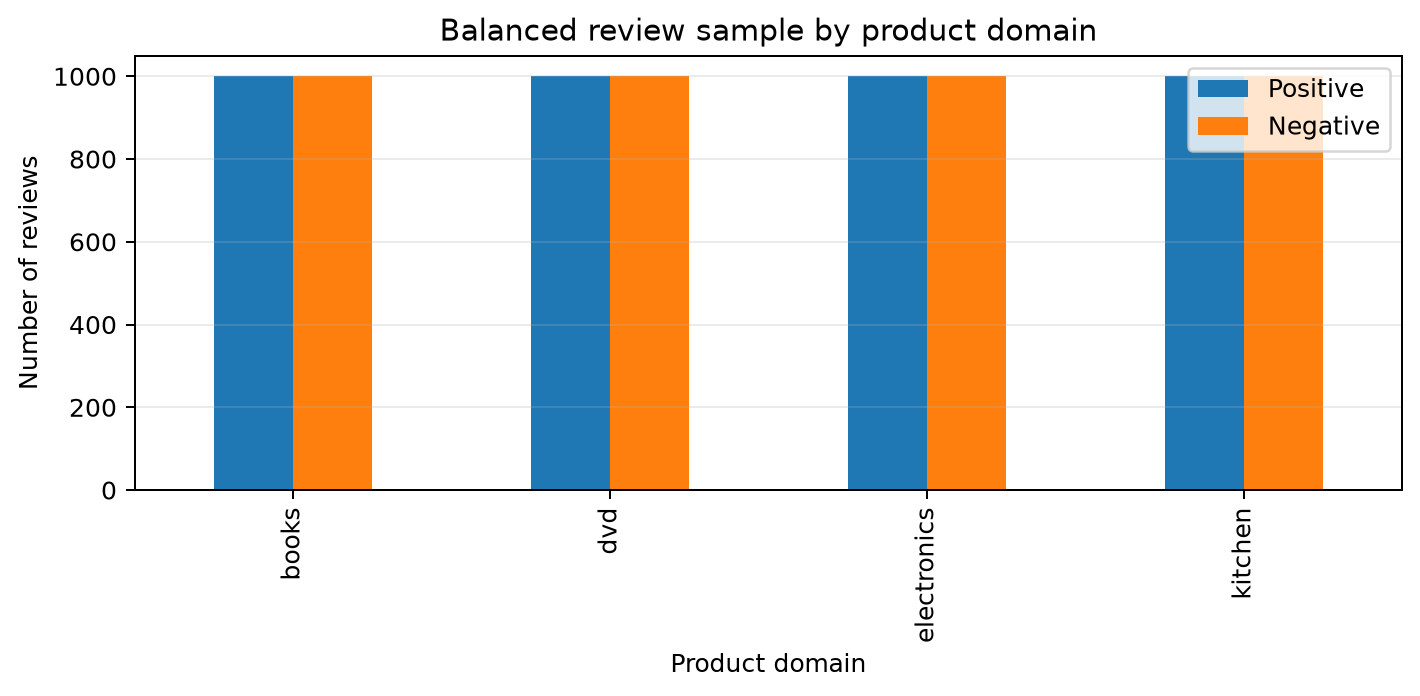

top_source_features.png


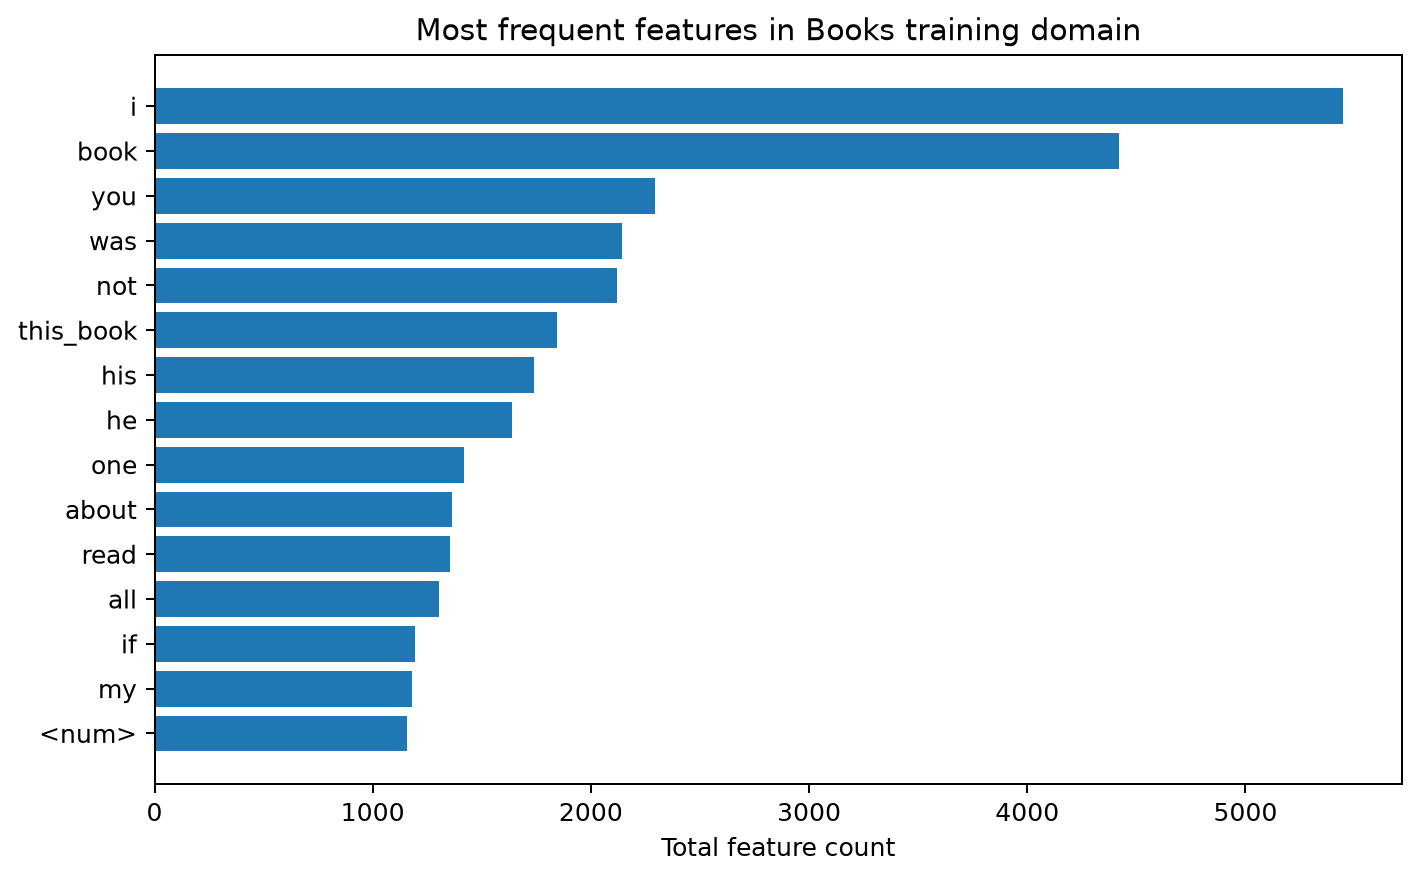

model_adaptation_gap.png


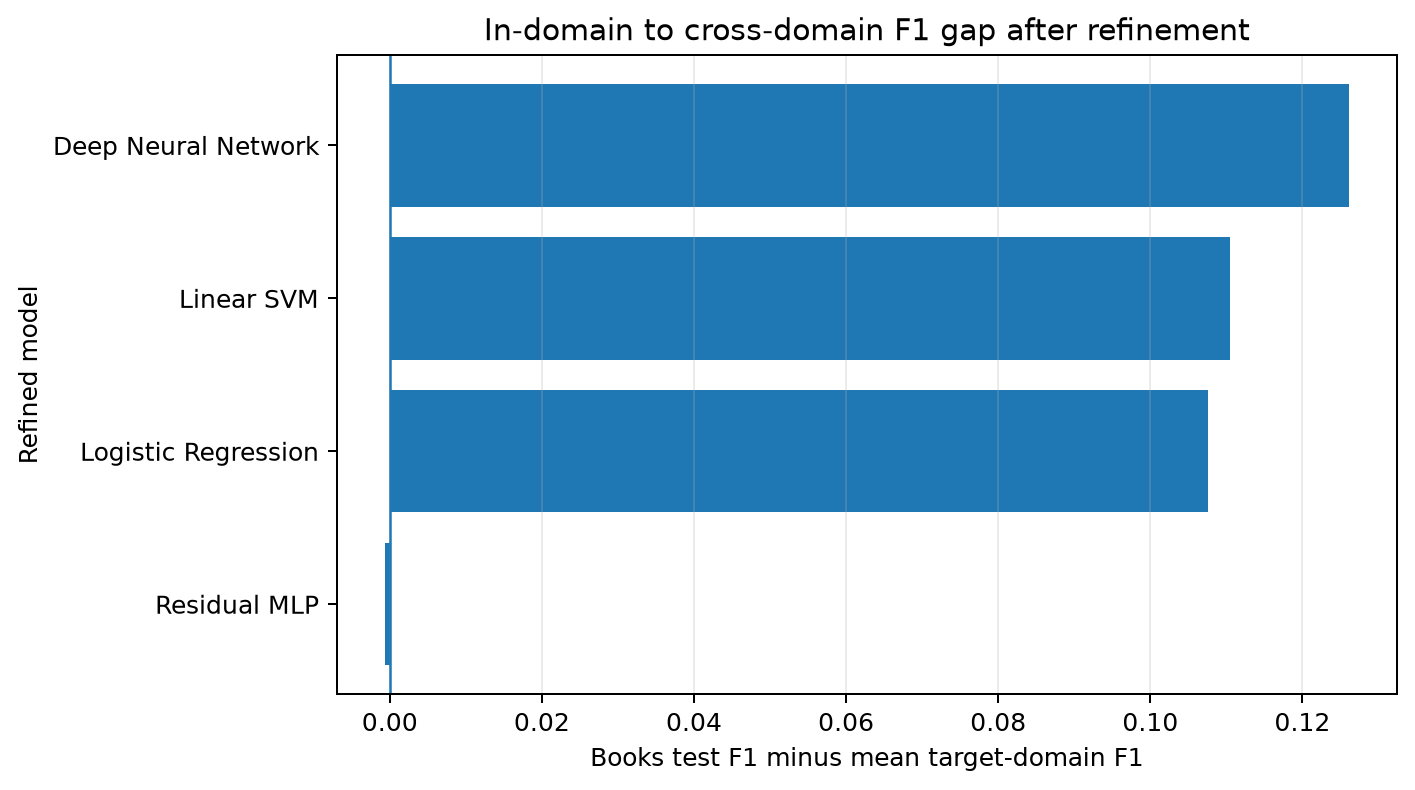

In [6]:
for filename in ['domain_class_balance.png', 'top_source_features.png', 'model_adaptation_gap.png']:
    print(filename)
    display(Image(filename=str(RESULTS_DIR / 'figures' / filename)))

## 6. Saved outputs

The experiment creates the dataset summaries, unified evaluation metrics, refinement log, model comparison figures and confusion matrices. The report build step reads these outputs and inserts the measured results. No metric is manually entered.

In [7]:
print('Output files:')
for path in sorted(RESULTS_DIR.rglob('*')):
    if path.is_file(): print(path.relative_to(ROOT))

Output files:
results/.gitkeep
results/dataset_summary.csv
results/dataset_summary_full.csv
results/experiment_metadata.json
results/figures/confusion_deep_neural_network_cross_domain_dvd.png
results/figures/confusion_deep_neural_network_cross_domain_electronics.png
results/figures/confusion_deep_neural_network_cross_domain_kitchen.png
results/figures/confusion_deep_neural_network_in_domain.png
results/figures/confusion_linear_svm_cross_domain_dvd.png
results/figures/confusion_linear_svm_cross_domain_electronics.png
results/figures/confusion_linear_svm_cross_domain_kitchen.png
results/figures/confusion_linear_svm_in_domain.png
results/figures/confusion_logistic_regression_cross_domain_dvd.png
results/figures/confusion_logistic_regression_cross_domain_electronics.png
results/figures/confusion_logistic_regression_cross_domain_kitchen.png
results/figures/confusion_logistic_regression_in_domain.png
results/figures/confusion_residual_mlp_cross_domain_dvd.png
results/figures/confusion_residu